# Laboratorio de Optimización — Sesión 1
## Paradigmas de implementación: problema, método y globalización

**Objetivos de la sesión**

1. Implementar la clase `Problem` con $f$, $\nabla f$ y contadores de evaluaciones.
2. Implementar el bucle genérico `descenso` y la búsqueda lineal `retroceso` (Armijo).
3. Comparar, sobre la función de Rosenbrock desde $x_0=(-1.2,\,1)$, el paso fijo
   $\alpha\in\{10^{-2},\,2\cdot 10^{-3},\,10^{-3}\}$ con el retroceso de Armijo
   ($\alpha_0=1$, $c_1=10^{-4}$, $\beta=1/2$), usando $d_k=-\nabla f(x_k)$ y $\varepsilon=10^{-6}$.
4. Formular el mismo problema en **Pyomo** y resolverlo con **IPOPT** como referencia.

### 0. Instalación (una sola vez)

Recomendado (conda / mamba):
```bash
conda install -c conda-forge numpy matplotlib pyomo ipopt
```
Alternativa con `pip`:
```bash
pip install numpy matplotlib pyomo idaes-pse
idaes get-extensions      # descarga binarios de IPOPT
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=False)

Matplotlib is building the font cache; this may take a moment.


### 1. El problema: clase `Problem`

Separamos el **problema** (qué se minimiza) del **método** (cómo se minimiza).
El problema cuenta sus evaluaciones: los métodos se comparan por llamadasa las evaluaciones de $f$ y sus derivadas, no sólo por iteraciones.

In [2]:
class Problem:
    # Problema sin restricciones min f(x) con información de primer orden.

    def __init__(self, f, grad, x0, nombre=""):
        self._f = f
        self._grad = grad
        self.x0 = np.asarray(x0, dtype=float)
        self.n = self.x0.size
        self.nombre = nombre
        self.reset()

    def reset(self):
        self.nf = 0   # evaluaciones de f
        self.ng = 0   # evaluaciones de grad f

    def f(self, x):
        self.nf += 1
        return self._f(x)

    def grad(self, x):
        self.ng += 1
        return self._grad(x)

### 2. Función de Rosenbrock

$$
f(x)=100\,(x_2-x_1^2)^2+(1-x_1)^2,\qquad
\nabla f(x)=\begin{pmatrix}-400\,x_1(x_2-x_1^2)-2(1-x_1)\\ 200\,(x_2-x_1^2)\end{pmatrix},
$$
con $x^*=(1,1)$, $f(x^*)=0$ y
$\nabla^2 f(x^*)=\begin{pmatrix}802&-400\\-400&200\end{pmatrix}$.

In [3]:


prob = Problem(rosen, rosen_grad, x0=[-1.2, 1.0], nombre="Rosenbrock")
print("f(x0)    =", prob.f(prob.x0))
print("grad(x*) =", rosen_grad(np.array([1.0, 1.0])))

f(x0)    = 24.199999999999996
grad(x*) = [-0.  0.]


**Verificación rápida del gradiente** con diferencias centradas (tema de la sesión 2):
el error relativo debe ser del orden de $h^2$.

In [4]:
def verificar_gradiente(f, grad, x, h=1e-6):
    g_fd = np.array([(f(x + h * e) - f(x - h * e)) / (2 * h) for e in np.eye(x.size)])
    g = grad(x)
    return np.linalg.norm(g - g_fd) / max(1.0, np.linalg.norm(g))

rng = np.random.default_rng(0)
for _ in range(3):
    x = rng.normal(size=2)
    print(f"x = {x},  error relativo = {verificar_gradiente(rosen, rosen_grad, x):.2e}")

x = [ 0.12573  -0.132105],  error relativo = 1.74e-11
x = [0.640423 0.1049  ],  error relativo = 3.21e-11
x = [-0.535669  0.361595],  error relativo = 2.53e-11


**Condicionamiento en la solución.** Los autovalores de $\nabla^2 f(x^*)$ determinan la constante
de Lipschitz local $L\approx\lambda_{\max}$ y, por tanto, el umbral $2/L$ del paso fijo.

In [5]:
H = rosen_hess(np.array([1.0, 1.0]))
lam = np.linalg.eigvalsh(H)
print("autovalores    :", lam)
print("kappa          :", lam[-1] / lam[0])
print("2/lambda_max   :", 2 / lam[-1])

autovalores    : [3.993608e-01 1.001601e+03]
kappa          : 2508.009601277454
2/lambda_max   : 0.0019968038374381654


### 3. El método: bucle genérico `descenso`

Las dos decisiones del algoritmo se pasan como funciones:

* `direccion(prob, x, g)` → paradigma 2 (modelo local);
* `paso(prob, x, d, g)` → paradigma 3 (globalización).

Criterios de parada: estacionariedad relativa
$\|\nabla f(x_k)\|\le\varepsilon\max\{1,\|\nabla f(x_0)\|\}$, presupuesto de iteraciones y,
además, detección de **divergencia** (valores no finitos). Siempre se devuelve el motivo de parada.

> Nota: el historial guarda $f(x_k)$ usando la función interna `prob._f`, que **no** incrementa el
> contador; así los contadores reflejan sólo las evaluaciones que el método necesita.

In [6]:
def descenso(prob, x0, direccion, paso, tol=1e-6, maxit=1000):
    x = np.asarray(x0, dtype=float).copy()
    g = prob.grad(x)
    ng0 = np.linalg.norm(g)
    historial = {"f": [], "ng": [], "alpha": []}
    for k in range(maxit):
        ng = np.linalg.norm(g)
        fx = prob._f(x)                          # no se cuenta
        historial["f"].append(fx)
        historial["ng"].append(ng)
        if not (np.isfinite(fx) and np.isfinite(ng)):
            return x, historial, "divergencia"
        if ng <= tol * max(1.0, ng0):
            return x, historial, "convergencia"
        d = direccion(prob, x, g)                # paradigma 2
        alpha = paso(prob, x, d, g)              # paradigma 3
        historial["alpha"].append(alpha)
        x = x + alpha * d
        g = prob.grad(x)
    return x, historial, "maxit"

### 4. Direcciones y reglas de paso

**Dirección de máximo descenso:** $d_k=-\nabla f(x_k)$.

**Paso fijo:** $\alpha_k=\alpha$.

**Retroceso de Armijo:** se acepta el primer $\alpha=\alpha_0\beta^j$ tal que
$f(x_k+\alpha d_k)\le f(x_k)+c_1\,\alpha\,\nabla f(x_k)^\top d_k$.
El control `pendiente >= 0` traduce la hipótesis de la proposición: sin dirección de descenso
no hay garantía de terminación.

In [7]:
def max_descenso(prob, x, g):
    return -g

def paso_fijo(alpha):
    def paso(prob, x, d, g):
        return alpha
    return paso

def retroceso(prob, x, d, g, alpha0=1.0, c1=1e-4, beta=0.5, maxit=60):
    fx = prob.f(x)
    pendiente = g @ d
    if pendiente >= 0:
        raise ValueError("d no es direccion de descenso")
    alpha = alpha0
    for _ in range(maxit):
        if prob.f(x + alpha * d) <= fx + c1 * alpha * pendiente:
            return alpha
        alpha *= beta
    raise RuntimeError("Armijo no satisfecho")

### 5. Experimentos

Mismo punto inicial, misma dirección, misma tolerancia; sólo cambia la regla de paso.
Usamos un presupuesto amplio de iteraciones para ver el comportamiento asintótico.

In [8]:
MAXIT = 50_000
TOL = 1e-6

estrategias = {
    r"fijo $\alpha=10^{-2}$":          paso_fijo(1e-2),
    r"fijo $\alpha=2\cdot10^{-3}$":    paso_fijo(2e-3),
    r"fijo $\alpha=10^{-3}$":          paso_fijo(1e-3),
    "Armijo":                          retroceso,
}

resultados = {}
with np.errstate(over="ignore", invalid="ignore"):
    for nombre, paso in estrategias.items():
        prob.reset()
        x, hist, motivo = descenso(prob, prob.x0, max_descenso, paso, tol=TOL, maxit=MAXIT)
        resultados[nombre] = dict(x=x, hist=hist, motivo=motivo,
                                  it=len(hist["ng"]) - 1, nf=prob.nf, ng=prob.ng)

print(f"{'estrategia':30s} {'motivo':>13s} {'iter':>7s} {'#f':>8s} {'#grad':>7s} "
      f"{'||x-x*||':>10s} {'||grad f||':>11s}")
for nombre, r in resultados.items():
    err = np.linalg.norm(r["x"] - 1.0)
    print(f"{nombre:30s} {r['motivo']:>13s} {r['it']:7d} {r['nf']:8d} {r['ng']:7d} "
          f"{err:10.2e} {r['hist']['ng'][-1]:11.2e}")

estrategia                            motivo    iter       #f   #grad   ||x-x*||  ||grad f||
fijo $\alpha=10^{-2}$            divergencia       6        0       7   1.12e+78         inf
fijo $\alpha=2\cdot10^{-3}$     convergencia    9175        0    9176   5.83e-04    2.33e-04
fijo $\alpha=10^{-3}$           convergencia   18433        0   18434   5.83e-04    2.33e-04
Armijo                          convergencia    7052    77076    7053   4.03e-04    2.30e-04


### 6. Gráficas: $\|\nabla f(x_k)\|$ en escala logarítmica

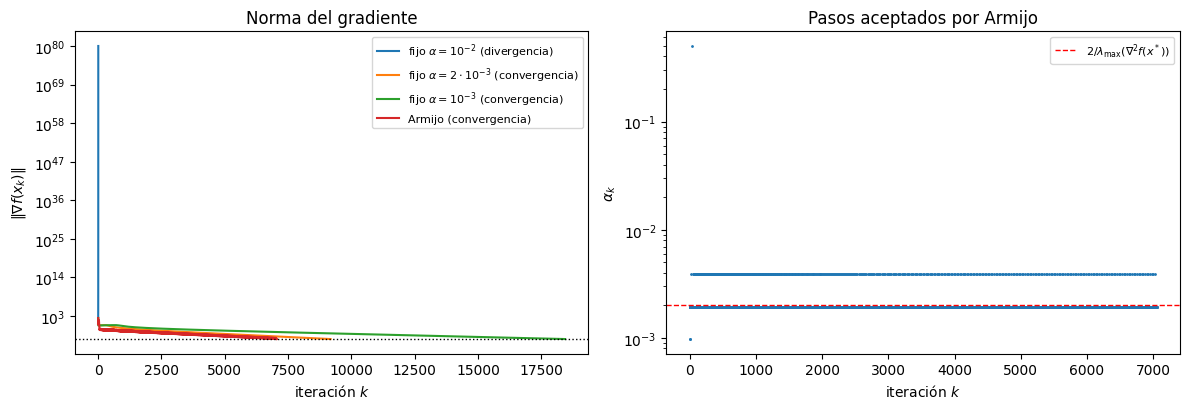

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for nombre, r in resultados.items():
    ng = np.array(r["hist"]["ng"])
    ng = ng[np.isfinite(ng)]
    ax[0].semilogy(ng, label=f"{nombre} ({r['motivo']})")
ax[0].axhline(TOL * max(1.0, resultados["Armijo"]["hist"]["ng"][0]), ls=":", c="k", lw=1)
ax[0].set_xlabel("iteración $k$"); ax[0].set_ylabel(r"$\|\nabla f(x_k)\|$")
ax[0].set_title("Norma del gradiente"); ax[0].legend(fontsize=8)

alphas = resultados["Armijo"]["hist"]["alpha"]
ax[1].semilogy(alphas, ".", ms=2)
ax[1].axhline(2 / lam[-1], ls="--", c="r", lw=1, label=r"$2/\lambda_{\max}(\nabla^2 f(x^*))$")
ax[1].set_xlabel("iteración $k$"); ax[1].set_ylabel(r"$\alpha_k$")
ax[1].set_title("Pasos aceptados por Armijo"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7. Trayectorias sobre las curvas de nivel

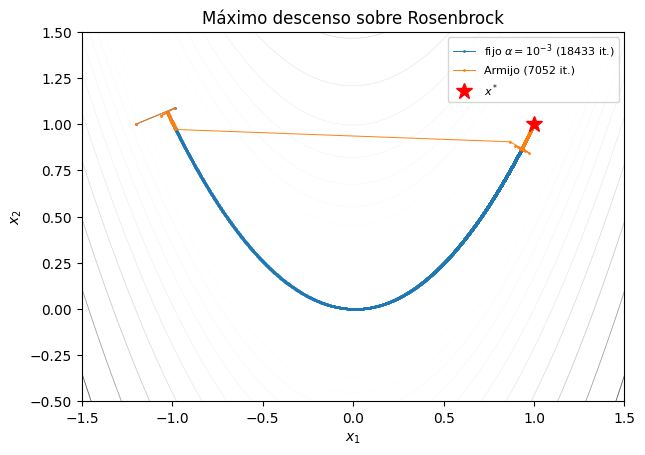

In [10]:
def trayectoria(paso, maxit=MAXIT):
    # Repite la corrida guardando los iterados.
    xs = [prob.x0.copy()]
    def paso_reg(p, x, d, g):
        a = paso(p, x, d, g)
        xs.append(x + a * d)
        return a
    with np.errstate(over="ignore", invalid="ignore"):
        descenso(prob, prob.x0, max_descenso, paso_reg, tol=TOL, maxit=maxit)
    return np.array(xs)

X1, X2 = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-0.5, 1.5, 400))
Z = 100 * (X2 - X1**2)**2 + (1 - X1)**2

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.contour(X1, X2, Z, levels=np.logspace(-1, 3, 25), cmap="Greys", linewidths=0.6)
for nombre in [r"fijo $\alpha=10^{-3}$", "Armijo"]:
    xs = trayectoria(estrategias[nombre])
    ax.plot(xs[:, 0], xs[:, 1], ".-", ms=2, lw=0.7, label=f"{nombre} ({len(xs)-1} it.)")
ax.plot(1, 1, "r*", ms=12, label="$x^*$")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(fontsize=8)
ax.set_title("Máximo descenso sobre Rosenbrock")
plt.show()

### 8. Preguntas para discutir

1. ¿Qué ocurre con $\alpha=10^{-2}$? Relacione con la proposición
   $f(x_{k+1})\le f(x_k)-\alpha\bigl(1-\tfrac{\alpha L}{2}\bigr)\|\nabla f(x_k)\|^2$
   y con el valor $2/\lambda_{\max}$ calculado arriba. (Recuerde que $\nabla f$ no es globalmente
   Lipschitz: lejos de $x^*$ la curvatura puede ser mucho mayor.)
2. Con $\varepsilon=10^{-6}$ ambos pasos fijos $2\cdot10^{-3}$ y $10^{-3}$ "convergen". Sin embargo
   $2\cdot10^{-3}>2/\lambda_{\max}\approx 1.997\cdot10^{-3}$. Ejecute la celda siguiente con una tolerancia
   más exigente: ¿qué ocurre y por qué? (Piense en la iteración lineal
   $e_{k+1}=(I-\alpha\nabla^2 f(x^*))\,e_k$ y en el factor $|1-\alpha\lambda_{\max}|$.)
3. Compare iteraciones **y** evaluaciones de $f$: ¿cuánto cuesta cada iteración de Armijo?
4. ¿El retroceso resuelve el problema de la *robustez*, el de la *velocidad*, o ambos?
   Observe la gráfica de $\alpha_k$ frente a $2/\lambda_{\max}$ y el número de condición $\kappa$.

In [11]:
# Pregunta 2: tolerancia mas exigente
for alpha in [2e-3, 1e-3]:
    prob.reset()
    x, hist, motivo = descenso(prob, prob.x0, max_descenso, paso_fijo(alpha),
                               tol=1e-8, maxit=100_000)
    print(f"alpha={alpha:.0e}: {motivo:>13s}, {len(hist['ng'])-1:6d} it., "
          f"||x-x*||={np.linalg.norm(x-1):.2e}, factor |1-alpha*lmax|={abs(1-alpha*lam[-1]):.4f}")

alpha=2e-03:         maxit,  99999 it., ||x-x*||=2.74e-03, factor |1-alpha*lmax|=1.0032


alpha=1e-03:  convergencia,  29960 it., ||x-x*||=5.83e-06, factor |1-alpha*lmax|=0.0016


### 9. El mismo problema en Pyomo, resuelto con IPOPT

Formulamos Rosenbrock como modelo algebraico. Pyomo construye $f$, $\nabla f$ y $\nabla^2 f$
por diferenciación automática (vía AMPL/ASL) y se los entrega a IPOPT, un método de Newton
globalizado. Servirá como **referencia** para todos los métodos que implementemos.

In [12]:
import pyomo.environ as pyo
try:
    import idaes  # si IPOPT se instalo con `idaes get-extensions`, esto lo agrega al PATH
except ImportError:
    pass

def modelo_rosenbrock(x0=(-1.2, 1.0)):
    m = pyo.ConcreteModel(name="Rosenbrock")
    m.I = pyo.RangeSet(1, 2)
    m.x = pyo.Var(m.I, initialize={1: x0[0], 2: x0[1]})
    m.obj = pyo.Objective(expr=100 * (m.x[2] - m.x[1]**2)**2 + (1 - m.x[1])**2,
                          sense=pyo.minimize)
    return m

m = modelo_rosenbrock()
m.pprint()

1 RangeSet Declarations
    I : Dimen=1, Size=2, Bounds=(1, 2)
        Key  : Finite : Members
        None :   True :   [1:2]

1 Var Declarations
    x : Size=2, Index=I
        Key : Lower : Value : Upper : Fixed : Stale : Domain
          1 :  None :  -1.2 :  None : False : False :  Reals
          2 :  None :   1.0 :  None : False : False :  Reals

1 Objective Declarations
    obj : Size=1, Index=None, Active=True
        Key  : Active : Sense    : Expression
        None :   True : minimize : 100*(x[2] - x[1]**2)**2 + (1 - x[1])**2

3 Declarations: I x obj


In [13]:
solver = pyo.SolverFactory("ipopt")
if not solver.available(exception_flag=False):
    print("IPOPT no está disponible: revise la sección 0 (instalación).")
else:
    solver.options["tol"] = 1e-10
    res = solver.solve(m, tee=False)
    print("estado      :", res.solver.status, "/", res.solver.termination_condition)
    x_ipopt = np.array([pyo.value(m.x[i]) for i in m.I])
    print("x*          :", x_ipopt)
    print("f(x*)       :", pyo.value(m.obj))
    print("||grad f||  :", np.linalg.norm(rosen_grad(x_ipopt)))

estado      : ok / optimal
x*          : [1. 1.]
f(x*)       : 0.0
||grad f||  : 0.0


**Del modelo Pyomo a nuestro `Problem`.** Podemos evaluar la expresión del objetivo de Pyomo
desde Python y usarla como información de orden cero; el gradiente lo obtenemos por diferenciación
simbólica de Pyomo (`differentiate`). Así el **mismo modelo** alimenta a IPOPT y a nuestros métodos.

In [14]:
from pyomo.core.expr.calculus.derivatives import differentiate

def problem_desde_pyomo(m):
    vars_ = [m.x[i] for i in m.I]
    dexpr = differentiate(m.obj.expr, wrt_list=vars_,
                          mode=differentiate.Modes.reverse_symbolic)
    def cargar(x):
        for v, xi in zip(vars_, x):
            v.set_value(float(xi), skip_validation=True)
    def f(x):
        cargar(x); return pyo.value(m.obj.expr)
    def grad(x):
        cargar(x); return np.array([pyo.value(e) for e in dexpr])
    x0 = [pyo.value(v) for v in vars_]
    return Problem(f, grad, x0, nombre=m.name)

m2 = modelo_rosenbrock()
prob_py = problem_desde_pyomo(m2)
x, hist, motivo = descenso(prob_py, prob_py.x0, max_descenso, retroceso, tol=TOL, maxit=MAXIT)
print(f"{motivo}: {len(hist['ng'])-1} it., #f={prob_py.nf}, #grad={prob_py.ng}, x={x}")
print("coincide con la versión NumPy:",
      np.allclose(x, resultados['Armijo']['x']))

convergencia: 7052 it., #f=77076, #grad=7053, x=[0.99982 0.99964]
coincide con la versión NumPy: True


### 10. Resumen

* Todo algoritmo del curso se describe con cuatro decisiones: información usada (orden cero, uno o dos), modelo local,
  globalización y tratamiento de restricciones.
* El paso fijo requiere conocer $L$; demasiado grande diverge, demasiado pequeño es lento.
* Armijo elige el paso automáticamente (**robustez**), pero con $d_k=-\nabla f(x_k)$ la
  convergencia sigue siendo lenta por el mal condicionamiento: la **velocidad** exige mejores
  modelos locales (Newton, cuasi-Newton).

**Próxima sesión:** cálculo y verificación de derivadas.